In [1]:
%cd /content
!rm -rf CityFlow
!git clone --recursive https://github.com/cityflow-project/CityFlow.git

%cd /content/CityFlow
!rm -rf extern/pybind11
!git clone --depth 1 --branch v2.13.6 https://github.com/pybind/pybind11.git extern/pybind11
!rm -rf build
!python -m pip install --no-cache-dir --no-build-isolation .

import cityflow
print("SUCCESS: CityFlow is installed and ready!")

/content
Cloning into 'CityFlow'...
remote: Enumerating objects: 785, done.
remote: Counting objects: 100% (329/329), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 785 (delta 281), reused 268 (delta 268), pack-reused 456 (from 1)
Receiving objects: 100% (785/785), 328.04 KiB | 3.77 MiB/s, done.
Resolving deltas: 100% (461/461), done.
Submodule 'extern/pybind11' (https://github.com/cityflow-project/pybind11.git) registered for path 'extern/pybind11'
Submodule 'extern/rapidjson' (https://github.com/cityflow-project/rapidjson.git) registered for path 'extern/rapidjson'
Cloning into '/content/CityFlow/extern/pybind11'...
remote: Enumerating objects: 54, done.        
remote: Total 54 (delta 0), reused 0 (delta 0), pack-reused 54 (from 1)        
Receiving objects: 100% (54/54), 165.17 KiB | 3.06 MiB/s, done.
Cloning into '/content/CityFlow/extern/rapidjson'...
remote: Enumerating objects: 44, done.        
remote: Total 44 (delta 0), reused 0 (delta 0), pack-reused 4

In [2]:
%cd /content
!rm -rf sample-code
!git clone --depth 1 https://github.com/traffic-signal-control/sample-code.git

import os, json

DATA_DIR = "/content/sample-code/data/manhattan_16x3/"
ROADNET_FILE = "roadnet_16_3.json"
FLOW_FILE = "anon_16_3_newyork_real.json"

with open(DATA_DIR + ROADNET_FILE) as f:
    roadnet = json.load(f)
with open(DATA_DIR + FLOW_FILE) as f:
    flow = json.load(f)

road_ids = {r["id"] for r in roadnet["roads"]}
invalid = sum(1 for v in flow if any(rd not in road_ids for rd in v["route"]))
real_ints = [i for i in roadnet["intersections"] if not i.get("virtual", False)]
start_times = [v["startTime"] for v in flow]

print("Intersections (total):", len(roadnet["intersections"]))
print("Intersections (signalised):", len(real_ints))
print("Roads:", len(roadnet["roads"]))
print("Vehicles in flow file:", len(flow))
print("Vehicle start times:", min(start_times), "to", max(start_times), "seconds")
print("Vehicles with invalid routes:", invalid)

assert invalid == 0, "Flow file does not match the roadnet!"
print("\nDataset verified: roadnet and flow match.")

/content
Cloning into 'sample-code'...
remote: Enumerating objects: 135, done.
remote: Counting objects: 100% (135/135), done.
remote: Compressing objects: 100% (109/109), done.
remote: Total 135 (delta 27), reused 123 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (135/135), 6.31 MiB | 4.07 MiB/s, done.
Resolving deltas: 100% (27/27), done.
Intersections (total): 86
Intersections (signalised): 48
Roads: 230
Vehicles in flow file: 2824
Vehicle start times: 0 to 3599 seconds
Vehicles with invalid routes: 0

Dataset verified: roadnet and flow match.


In [3]:
import cityflow

config = {
    "interval": 1.0,
    "seed": 0,
    "dir": DATA_DIR,
    "roadnetFile": ROADNET_FILE,
    "flowFile": FLOW_FILE,
    "rlTrafficLight": True,
    "saveReplay": False,
    "laneChange": False
}

with open("/content/config.json", "w") as f:
    json.dump(config, f, indent=4)

engine = cityflow.Engine("/content/config.json", thread_num=1)

for _ in range(300):
    engine.next_step()

n = engine.get_vehicle_count()
print("Simulation time:", engine.get_current_time())
print("Vehicles in network after 300 s:", n)

assert n > 0, "No vehicles spawned. Check the config."
print("\nSimulator works and vehicles are spawning.")

Simulation time: 300.0
Vehicles in network after 300 s: 224

Simulator works and vehicles are spawning.


In [4]:
import numpy as np
import pandas as pd
import random
import collections

# ---- busiest signalised intersection ----
end_inter = {r["id"]: r["endIntersection"] for r in roadnet["roads"]}
load = collections.Counter()
for v in flow:
    for rd in v["route"][:-1]:
        load[end_inter[rd]] += 1

inter_map = {i["id"]: i for i in real_ints}
TARGET_ID = next(k for k, _ in load.most_common() if k in inter_map)
target = inter_map[TARGET_ID]

incoming_roads = [r for r in roadnet["roads"] if r["endIntersection"] == TARGET_ID]
incoming_lanes = [f'{r["id"]}_{k}' for r in incoming_roads for k in range(len(r["lanes"]))]

phases = target["trafficLight"]["lightphases"]
ACTIONS = list(range(1, len(phases)))     # phase 0 = clearance, excluded

# lanes served by each phase
phase_lanes = {}
for p in ACTIONS:
    lanes = set()
    for link_idx in phases[p]["availableRoadLinks"]:
        link = target["roadLinks"][link_idx]
        for ll in link["laneLinks"]:
            lanes.add(f'{link["startRoad"]}_{ll["startLaneIndex"]}')
    phase_lanes[p] = sorted(lanes)

# ---- settings ----
MAX_SIM_TIME = 3600
ACTION_INTERVAL = 10
GREEN = 30   # fixed-time green length (multiple of ACTION_INTERVAL)

# ---- helpers ----
def fixed_phase(inter_id, t):
    n = len(inter_map[inter_id]["trafficLight"]["lightphases"]) - 1
    return 1 + int(t // GREEN) % n

def set_background(t):
    """All other intersections follow a fixed-time plan."""
    for iid in inter_map:
        if iid != TARGET_ID:
            engine.set_tl_phase(iid, fixed_phase(iid, t))

def lane_counts():
    vc = engine.get_lane_vehicle_count()
    wc = engine.get_lane_waiting_vehicle_count()
    return ([vc.get(l, 0) for l in incoming_lanes],
            [wc.get(l, 0) for l in incoming_lanes])

print("Target intersection:", TARGET_ID, f"({load[TARGET_ID]} vehicles pass through)")
print("Incoming roads:", len(incoming_roads))
print("Incoming lanes:", len(incoming_lanes))
print("Phases:", len(phases), "| Action set:", ACTIONS)
for p in ACTIONS:
    print(f"  Phase {p}: serves {len(phase_lanes[p])} lanes")

Target intersection: intersection_2_9 (843 vehicles pass through)
Incoming roads: 4
Incoming lanes: 12
Phases: 9 | Action set: [1, 2, 3, 4, 5, 6, 7, 8]
  Phase 1: serves 6 lanes
  Phase 2: serves 6 lanes
  Phase 3: serves 6 lanes
  Phase 4: serves 6 lanes
  Phase 5: serves 6 lanes
  Phase 6: serves 6 lanes
  Phase 7: serves 6 lanes
  Phase 8: serves 6 lanes


In [5]:
def run_episode(policy="fixed", seed=0):
    rng = random.Random(seed)
    engine.reset()
    rows, waiting_log = [], []
    t, prev_phase = 0, 1

    while t < MAX_SIM_TIME:
        veh, wait = lane_counts()
        wait_map = dict(zip(incoming_lanes, wait))

        # pressure = waiting vehicles on lanes each phase serves
        pressure = {p: sum(wait_map.get(l, 0) for l in phase_lanes[p]) for p in ACTIONS}
        maxp = max(pressure.values())
        cands = [p for p in ACTIONS if pressure[p] == maxp]
        best = prev_phase if prev_phase in cands else cands[0]

        # choose action
        if policy == "fixed":
            action = fixed_phase(TARGET_ID, t)
        elif policy == "random":
            action = rng.choice(ACTIONS)
        elif policy == "maxpressure":
            action = best
        elif policy == "mixed":
            action = rng.choice(ACTIONS) if rng.random() < 0.3 else best
        else:
            raise ValueError(policy)

        total_wait_now = sum(wait)

        set_background(t)
        engine.set_tl_phase(TARGET_ID, action)
        for _ in range(ACTION_INTERVAL):
            engine.next_step()
        t += ACTION_INTERVAL

        _, wait_next = lane_counts()
        total_wait_next = sum(wait_next)
        waiting_log.append(total_wait_next)

        row = {"time": t - ACTION_INTERVAL}
        row.update({f"veh_{i}": v for i, v in enumerate(veh)})
        row.update({f"wait_{i}": w for i, w in enumerate(wait)})
        row.update({"current_phase": prev_phase, "action": action,
                    "best_phase": best, "total_wait_now": total_wait_now,
                    "total_wait_next": total_wait_next, "policy": policy})
        rows.append(row)
        prev_phase = action

    summary = {
        "policy": policy,
        "avg_travel_time_s": engine.get_average_travel_time(),
        "avg_waiting_vehicles": float(np.mean(waiting_log)),
        "max_waiting_vehicles": int(np.max(waiting_log)),
    }
    return rows, summary


# ---- fixed-time baseline ----
_, baseline = run_episode("fixed")
print("FIXED-TIME BASELINE")
print("-------------------")
print(f"Target intersection:      {TARGET_ID}")
print(f"Avg travel time (s):      {baseline['avg_travel_time_s']:.2f}")
print(f"Avg waiting vehicles:     {baseline['avg_waiting_vehicles']:.2f}")
print(f"Max waiting vehicles:     {baseline['max_waiting_vehicles']}")

FIXED-TIME BASELINE
-------------------
Target intersection:      intersection_2_9
Avg travel time (s):      1008.54
Avg waiting vehicles:     9.18
Max waiting vehicles:     25


In [6]:
os.makedirs("/content/results", exist_ok=True)

episodes = (
    [("fixed", 0)] +
    [("random", s) for s in range(1, 6)] +
    [("mixed", s) for s in range(11, 16)]
)

all_rows, summaries = [], []
for ep, (policy, seed) in enumerate(episodes, 1):
    rows, summ = run_episode(policy, seed)
    for r in rows:
        r["episode"] = ep
    all_rows.extend(rows)
    summaries.append(summ)
    print(f"Episode {ep}/{len(episodes)} | {policy:6s} | "
          f"avg wait: {summ['avg_waiting_vehicles']:.2f} | "
          f"travel time: {summ['avg_travel_time_s']:.1f}s")

df = pd.DataFrame(all_rows)
df.to_csv("/content/results/traffic_dataset.csv", index=False)
pd.DataFrame(summaries).to_csv("/content/results/policy_summaries.csv", index=False)

print("\nDataset shape:", df.shape)
print("\nLabel distribution (best_phase):")
print(df["best_phase"].value_counts().sort_index())
print("\nFirst 5 rows:")
display(df.head())

Episode 1/11 | fixed  | avg wait: 9.18 | travel time: 1008.5s
Episode 2/11 | random | avg wait: 8.07 | travel time: 1037.7s
Episode 3/11 | random | avg wait: 9.69 | travel time: 1059.3s
Episode 4/11 | random | avg wait: 8.91 | travel time: 1045.4s
Episode 5/11 | random | avg wait: 7.10 | travel time: 1026.9s
Episode 6/11 | random | avg wait: 9.63 | travel time: 1045.6s
Episode 7/11 | mixed  | avg wait: 9.10 | travel time: 1014.6s
Episode 8/11 | mixed  | avg wait: 9.43 | travel time: 1017.1s
Episode 9/11 | mixed  | avg wait: 11.18 | travel time: 1019.1s
Episode 10/11 | mixed  | avg wait: 9.19 | travel time: 1013.7s
Episode 11/11 | mixed  | avg wait: 9.58 | travel time: 1020.9s

Dataset shape: (3960, 32)

Label distribution (best_phase):
best_phase
1     235
2    2758
3      38
4      91
5      50
6      30
7      32
8     726
Name: count, dtype: int64

First 5 rows:


,time,veh_0,veh_1,veh_2,veh_3,veh_4,veh_5,veh_6,veh_7,veh_8,...,wait_9,wait_10,wait_11,current_phase,action,best_phase,total_wait_now,total_wait_next,policy,episode
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,1,0,0,fixed,1
1,10,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,1,0,0,fixed,1
2,20,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,1,0,0,fixed,1
3,30,0,0,0,0,0,0,0,0,0,...,0,0,0,1,2,1,0,0,fixed,1
4,40,0,0,0,0,0,0,0,0,0,...,0,0,0,2,2,2,0,0,fixed,1


In [7]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
DATA_PATH = "/content/results/traffic_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("DATASET OVERVIEW")
print("================")
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nFIRST 5 RECORDS")
display(df.head())

print("\nDATA TYPES")
print(df.dtypes)
print("\nMISSING VALUES")
print(df.isnull().sum())
print("\nDUPLICATE RECORDS:", df.duplicated().sum())

df_clean = df.drop_duplicates().copy()
df_clean = df_clean.dropna(subset=["best_phase"])
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNUMERICAL FEATURES")
print(numeric_cols)

print("\nCATEGORICAL FEATURES")
print(categorical_cols)
print("\nDESCRIPTIVE STATISTICS")
display(
    df_clean[numeric_cols].describe().T.round(3)
)
statistics = pd.DataFrame({
    "Mean": df_clean[numeric_cols].mean(),
    "Median": df_clean[numeric_cols].median(),
    "Mode": df_clean[numeric_cols].mode().iloc[0],
    "Variance": df_clean[numeric_cols].var(),
    "Std_Deviation": df_clean[numeric_cols].std(),
    "Skewness": df_clean[numeric_cols].skew()
})
print("\nADDITIONAL STATISTICAL MEASURES")
display(statistics.round(3))
print("\nPOLICY DISTRIBUTION")
print(df_clean["policy"].value_counts())
print("\nBEST PHASE DISTRIBUTION")
print(df_clean["best_phase"].value_counts().sort_index())
os.makedirs("/content/results", exist_ok=True)

df_clean.to_csv(
    "/content/results/cleaned_traffic_dataset.csv",
    index=False
)

statistics.to_csv(
    "/content/results/descriptive_statistics.csv"
)

print("\n===================================")
print("TASK 1 COMPLETED SUCCESSFULLY")
print("===================================")
print("Cleaned dataset shape:", df_clean.shape)
print("Saved: cleaned_traffic_dataset.csv")
print("Saved: descriptive_statistics.csv")


DATASET OVERVIEW
Shape: (3960, 32)
Rows: 3960
Columns: 32

FIRST 5 RECORDS


,time,veh_0,veh_1,veh_2,veh_3,veh_4,veh_5,veh_6,veh_7,veh_8,...,wait_9,wait_10,wait_11,current_phase,action,best_phase,total_wait_now,total_wait_next,policy,episode
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,1,0,0,fixed,1
1,10,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,1,0,0,fixed,1
2,20,0,0,0,0,0,0,0,0,0,...,0,0,0,1,1,1,0,0,fixed,1
3,30,0,0,0,0,0,0,0,0,0,...,0,0,0,1,2,1,0,0,fixed,1
4,40,0,0,0,0,0,0,0,0,0,...,0,0,0,2,2,2,0,0,fixed,1



DATA TYPES
time                int64
veh_0               int64
veh_1               int64
veh_2               int64
veh_3               int64
veh_4               int64
veh_5               int64
veh_6               int64
veh_7               int64
veh_8               int64
veh_9               int64
veh_10              int64
veh_11              int64
wait_0              int64
wait_1              int64
wait_2              int64
wait_3              int64
wait_4              int64
wait_5              int64
wait_6              int64
wait_7              int64
wait_8              int64
wait_9              int64
wait_10             int64
wait_11             int64
current_phase       int64
action              int64
best_phase          int64
total_wait_now      int64
total_wait_next     int64
policy             object
episode             int64
dtype: object

MISSING VALUES
time               0
veh_0              0
veh_1              0
veh_2              0
veh_3              0
veh_4              0


,count,mean,std,min,25%,50%,75%,max
time,3960.0,1795.000,1039.358,0.0,897.5,1795.0,2692.5,3590.0
veh_0,3960.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
veh_1,3960.0,0.706,1.065,0.0,0.0,0.0,1.0,6.0
veh_2,3960.0,2.430,3.784,0.0,0.0,1.0,3.0,19.0
veh_3,3960.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
veh_4,3960.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
veh_5,3960.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
veh_6,3960.0,0.149,0.483,0.0,0.0,0.0,0.0,4.0
veh_7,3960.0,7.274,3.791,0.0,5.0,8.0,11.0,11.0
veh_8,3960.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0



ADDITIONAL STATISTICAL MEASURES


,Mean,Median,Mode,Variance,Std_Deviation,Skewness
time,1795.000,1795.0,0.0,1080264.461,1039.358,0.000
veh_0,0.000,0.0,0.0,0.000,0.000,0.000
veh_1,0.706,0.0,0.0,1.135,1.065,1.846
veh_2,2.430,1.0,0.0,14.320,3.784,2.101
veh_3,0.000,0.0,0.0,0.000,0.000,0.000
veh_4,0.000,0.0,0.0,0.000,0.000,0.000
veh_5,0.000,0.0,0.0,0.000,0.000,0.000
veh_6,0.149,0.0,0.0,0.233,0.483,3.752
veh_7,7.274,8.0,11.0,14.370,3.791,-0.703
veh_8,0.000,0.0,0.0,0.000,0.000,0.000



POLICY DISTRIBUTION
policy
random    1800
mixed     1800
fixed      360
Name: count, dtype: int64

BEST PHASE DISTRIBUTION
best_phase
1     235
2    2758
3      38
4      91
5      50
6      30
7      32
8     726
Name: count, dtype: int64

TASK 1 COMPLETED SUCCESSFULLY
Cleaned dataset shape: (3960, 32)
Saved: cleaned_traffic_dataset.csv
Saved: descriptive_statistics.csv


2) Exploratory Data Analysis and Data Visualization.

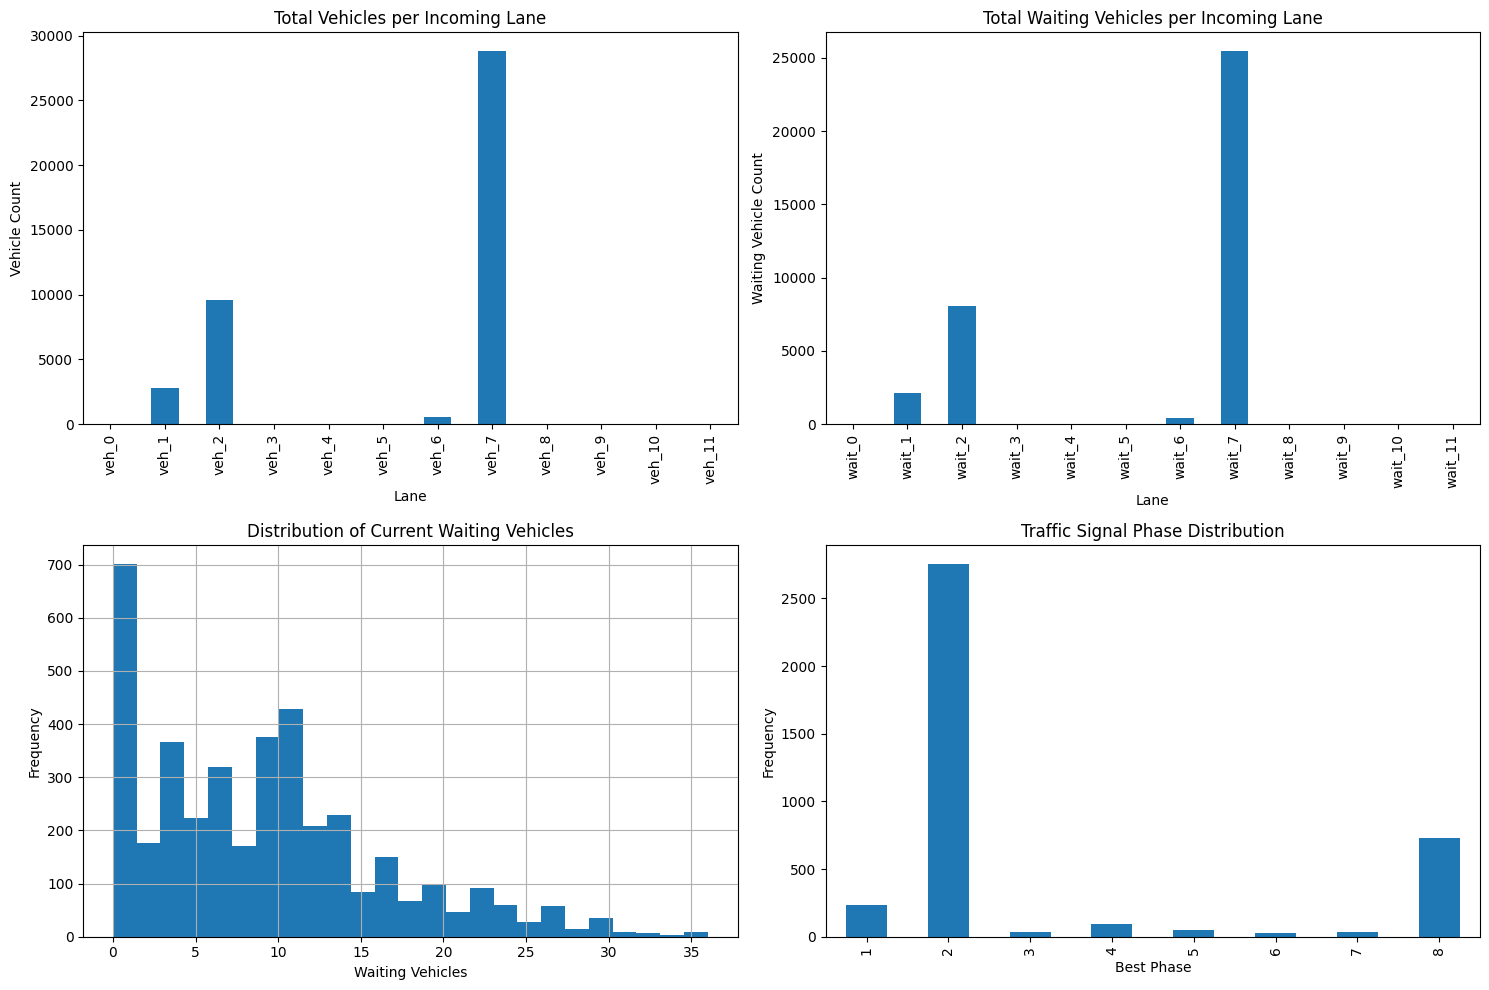

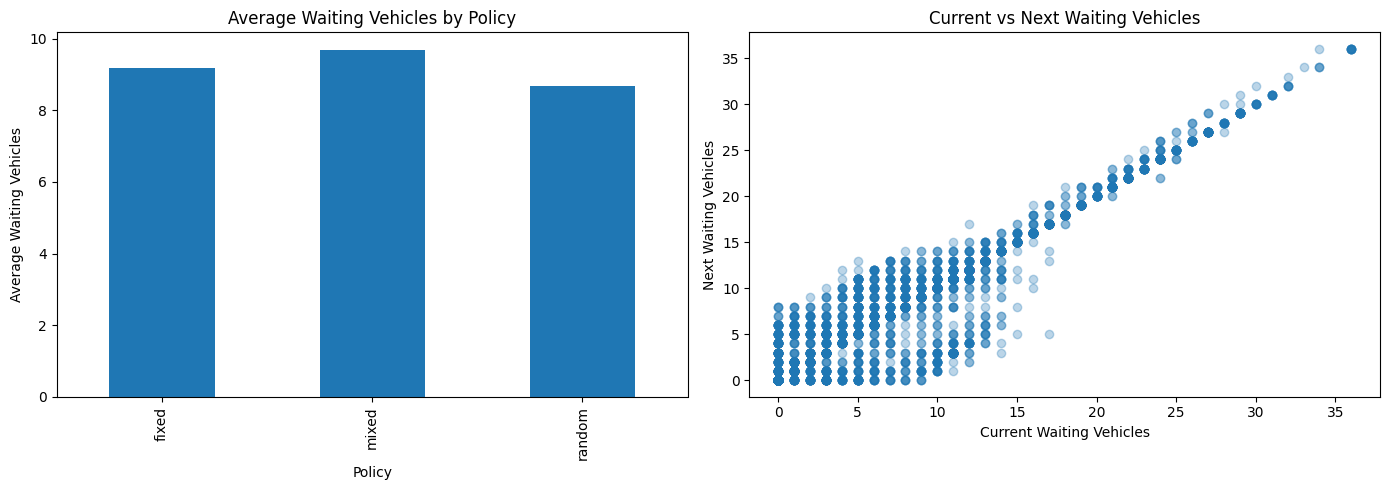

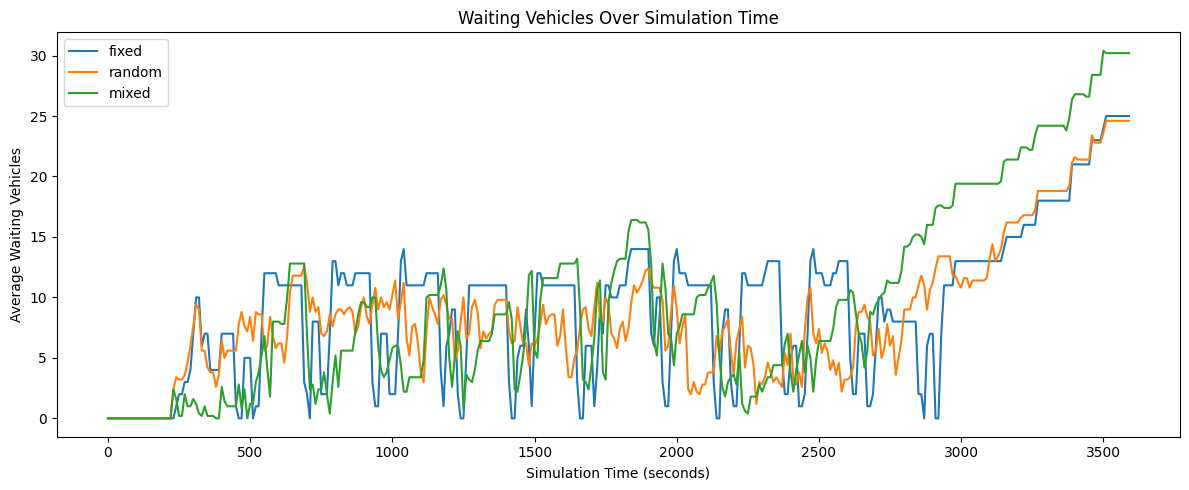

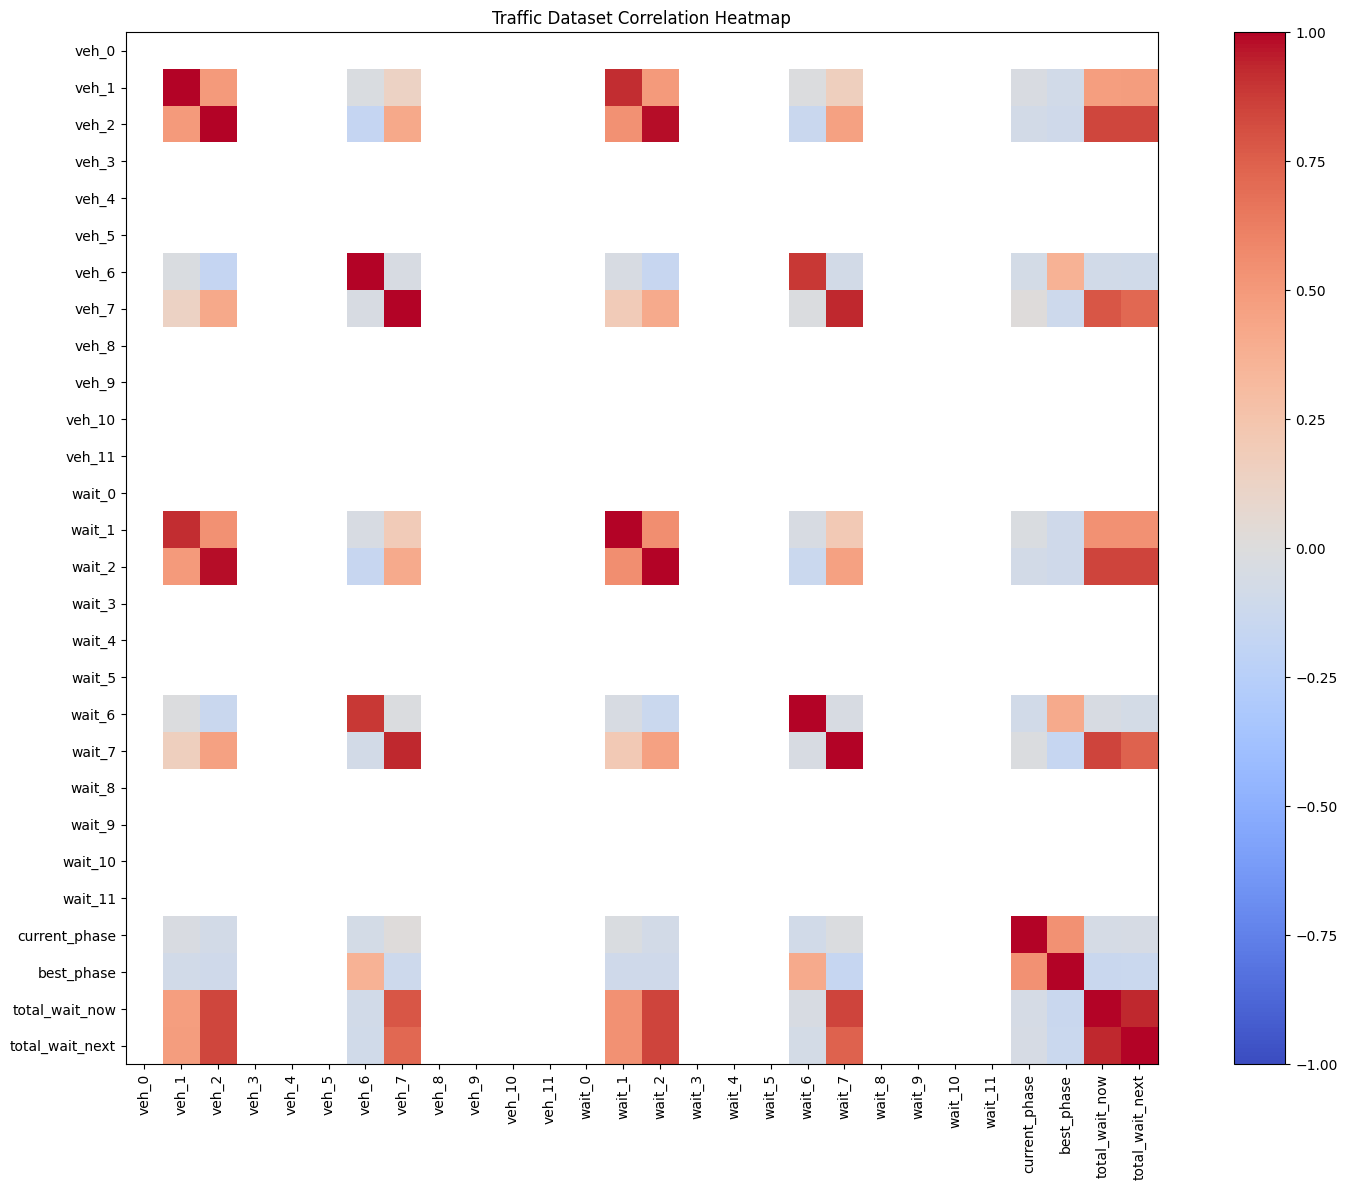

In [8]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("/content/results/cleaned_traffic_dataset.csv")

veh_cols = [c for c in df.columns if c.startswith("veh_")]
wait_cols = [c for c in df.columns if c.startswith("wait_")]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

df[veh_cols].sum().plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Total Vehicles per Incoming Lane")
axes[0, 0].set_xlabel("Lane")
axes[0, 0].set_ylabel("Vehicle Count")

df[wait_cols].sum().plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Total Waiting Vehicles per Incoming Lane")
axes[0, 1].set_xlabel("Lane")
axes[0, 1].set_ylabel("Waiting Vehicle Count")

df["total_wait_now"].hist(bins=25, ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Current Waiting Vehicles")
axes[1, 0].set_xlabel("Waiting Vehicles")
axes[1, 0].set_ylabel("Frequency")

df["best_phase"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1, 1]
)
axes[1, 1].set_title("Traffic Signal Phase Distribution")
axes[1, 1].set_xlabel("Best Phase")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

policy_wait = df.groupby("policy")["total_wait_next"].mean()
policy_wait.plot(kind="bar", ax=axes[0])
axes[0].set_title("Average Waiting Vehicles by Policy")
axes[0].set_xlabel("Policy")
axes[0].set_ylabel("Average Waiting Vehicles")

axes[1].scatter(
    df["total_wait_now"],
    df["total_wait_next"],
    alpha=0.3
)
axes[1].set_title("Current vs Next Waiting Vehicles")
axes[1].set_xlabel("Current Waiting Vehicles")
axes[1].set_ylabel("Next Waiting Vehicles")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))

for policy in df["policy"].unique():
    temp = df[df["policy"] == policy].groupby("time")[
        "total_wait_next"
    ].mean()
    ax.plot(temp.index, temp.values, label=policy)

ax.set_title("Waiting Vehicles Over Simulation Time")
ax.set_xlabel("Simulation Time (seconds)")
ax.set_ylabel("Average Waiting Vehicles")
ax.legend()
plt.tight_layout()
plt.show()

corr_cols = veh_cols + wait_cols + [
    "current_phase",
    "best_phase",
    "total_wait_now",
    "total_wait_next"
]

corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(16, 12))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=90)
ax.set_yticklabels(corr_cols)
ax.set_title("Traffic Dataset Correlation Heatmap")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

os.makedirs("/content/results/plots", exist_ok=True)

fig.savefig("/content/results/plots/correlation_heatmap.png", dpi=300)


3) Feature Engineering and Data Preparation

In [9]:

import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder

df = pd.read_csv("/content/results/cleaned_traffic_dataset.csv")

veh_cols = [c for c in df.columns if c.startswith("veh_")]
wait_cols = [c for c in df.columns if c.startswith("wait_")]

active_veh = [c for c in veh_cols if df[c].nunique() > 1]
active_wait = [c for c in wait_cols if df[c].nunique() > 1]

df["total_vehicles"] = df[active_veh].sum(axis=1)
df["total_waiting"] = df[active_wait].sum(axis=1)
df["max_lane_queue"] = df[active_wait].max(axis=1)
df["mean_lane_queue"] = df[active_wait].mean(axis=1)
df["vehicle_wait_ratio"] = (
    df["total_waiting"] / (df["total_vehicles"] + 1)
)

feature_cols = (
    active_veh
    + active_wait
    + [
        "time",
        "current_phase",
        "total_vehicles",
        "total_waiting",
        "max_lane_queue",
        "mean_lane_queue",
        "vehicle_wait_ratio"
    ]
)

X = df[feature_cols].copy()
y_class = df["best_phase"].astype(int)
y_reg = df["total_wait_next"].astype(float)
groups = df["episode"]

constant_cols = X.columns[X.nunique() <= 1].tolist()
X = X.drop(columns=constant_cols)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y_class, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train_class = y_class.iloc[train_idx]
y_test_class = y_class.iloc[test_idx]

y_train_reg = y_reg.iloc[train_idx]
y_test_reg = y_reg.iloc[test_idx]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train_class)
y_test_encoded = label_encoder.transform(y_test_class)

os.makedirs("/content/results", exist_ok=True)

X_train.to_csv("/content/results/X_train.csv", index=False)
X_test.to_csv("/content/results/X_test.csv", index=False)

np.save("/content/results/X_train_scaled.npy", X_train_scaled)
np.save("/content/results/X_test_scaled.npy", X_test_scaled)

np.save("/content/results/y_train_class.npy", y_train_encoded)
np.save("/content/results/y_test_class.npy", y_test_encoded)

np.save("/content/results/y_train_reg.npy", y_train_reg.to_numpy())
np.save("/content/results/y_test_reg.npy", y_test_reg.to_numpy())

print("ACTIVE VEHICLE LANES:", active_veh)
print("ACTIVE WAITING LANES:", active_wait)
print("REMOVED CONSTANT FEATURES:", constant_cols)
print("FINAL FEATURES:", feature_cols)
print("FINAL FEATURE COUNT:", X.shape[1])
print("TRAINING SAMPLES:", len(X_train))
print("TESTING SAMPLES:", len(X_test))
print("TRAINING EPISODES:", sorted(groups.iloc[train_idx].unique()))
print("TESTING EPISODES:", sorted(groups.iloc[test_idx].unique()))
print("\nCLASS DISTRIBUTION")
print(y_class.value_counts().sort_index())
print("\nTRAINING CLASS DISTRIBUTION")
print(y_train_class.value_counts().sort_index())
print("\nTESTING CLASS DISTRIBUTION")
print(y_test_class.value_counts().sort_index())
print("\nFEATURE MATRIX SHAPE:", X.shape)
print("\nTASK 3 COMPLETED")


ACTIVE VEHICLE LANES: ['veh_1', 'veh_2', 'veh_6', 'veh_7']
ACTIVE WAITING LANES: ['wait_1', 'wait_2', 'wait_6', 'wait_7']
REMOVED CONSTANT FEATURES: []
FINAL FEATURES: ['veh_1', 'veh_2', 'veh_6', 'veh_7', 'wait_1', 'wait_2', 'wait_6', 'wait_7', 'time', 'current_phase', 'total_vehicles', 'total_waiting', 'max_lane_queue', 'mean_lane_queue', 'vehicle_wait_ratio']
FINAL FEATURE COUNT: 15
TRAINING SAMPLES: 2880
TESTING SAMPLES: 1080
TRAINING EPISODES: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(11)]
TESTING EPISODES: [np.int64(1), np.int64(6), np.int64(10)]

CLASS DISTRIBUTION
best_phase
1     235
2    2758
3      38
4      91
5      50
6      30
7      32
8     726
Name: count, dtype: int64

TRAINING CLASS DISTRIBUTION
best_phase
1     191
2    2030
3      31
4      60
5      40
6      23
7      22
8     483
Name: count, dtype: int64

TESTING CLASS DISTRIBUTION
best_phase
1     44
2    728
3      7
4     31
5     10
6      7
7     1

4) Simple and Multiple Linear Regression

REGRESSION PERFORMANCE


,Model,MAE,MSE,RMSE,R2
0,Simple Linear Regression,1.5559,6.7379,2.5958,0.8564
1,Multiple Linear Regression,1.6372,5.8221,2.4129,0.8759


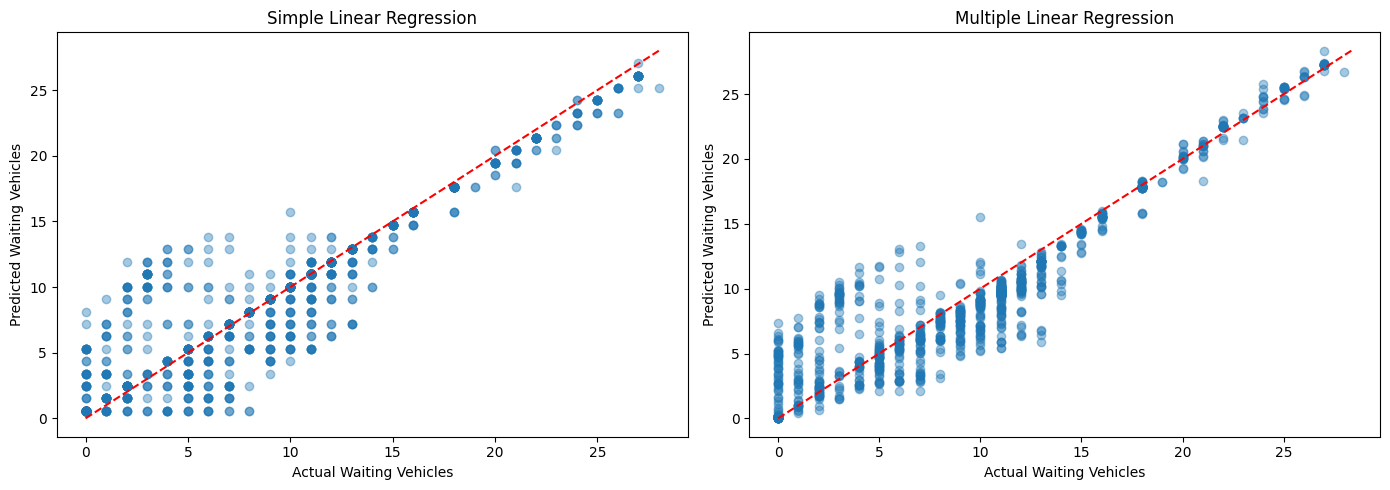

Simple Regression Coefficient: 0.9458155097920675
Simple Regression Intercept: 0.5669842939798784
Multiple Regression Intercept: 9.130555555555556

TASK 4 COMPLETED


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("/content/results/cleaned_traffic_dataset.csv")

X_simple_train = X_train[["total_waiting"]]
X_simple_test = X_test[["total_waiting"]]

simple_model = LinearRegression()
simple_model.fit(X_simple_train, y_train_reg)

simple_pred = simple_model.predict(X_simple_test)

multiple_model = LinearRegression()
multiple_model.fit(X_train_scaled, y_train_reg)

multiple_pred = multiple_model.predict(X_test_scaled)

def regression_metrics(actual, predicted, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

regression_results = pd.DataFrame([
    regression_metrics(y_test_reg, simple_pred, "Simple Linear Regression"),
    regression_metrics(y_test_reg, multiple_pred, "Multiple Linear Regression")
])

print("REGRESSION PERFORMANCE")
display(regression_results.round(4))

regression_results.to_csv(
    "/content/results/regression_results.csv",
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test_reg, simple_pred, alpha=0.4)
axes[0].plot(
    [0, max(y_test_reg.max(), simple_pred.max())],
    [0, max(y_test_reg.max(), simple_pred.max())],
    "r--"
)
axes[0].set_title("Simple Linear Regression")
axes[0].set_xlabel("Actual Waiting Vehicles")
axes[0].set_ylabel("Predicted Waiting Vehicles")

axes[1].scatter(y_test_reg, multiple_pred, alpha=0.4)
axes[1].plot(
    [0, max(y_test_reg.max(), multiple_pred.max())],
    [0, max(y_test_reg.max(), multiple_pred.max())],
    "r--"
)
axes[1].set_title("Multiple Linear Regression")
axes[1].set_xlabel("Actual Waiting Vehicles")
axes[1].set_ylabel("Predicted Waiting Vehicles")

plt.tight_layout()
plt.savefig(
    "/content/results/plots/linear_regression_comparison.png",
    dpi=300
)
plt.show()

print("Simple Regression Coefficient:", simple_model.coef_[0])
print("Simple Regression Intercept:", simple_model.intercept_)
print("Multiple Regression Intercept:", multiple_model.intercept_)

print("\nTASK 4 COMPLETED")


5) Decision Tree Classification

,Metric,Decision Tree
0,Accuracy,0.982407
1,Precision,0.986459
2,Recall,0.982407
3,F1 Score,0.983553


              precision    recall  f1-score   support

           1       0.73      0.98      0.83        44
           2       1.00      0.98      0.99       728
           3       1.00      1.00      1.00         7
           4       1.00      1.00      1.00        31
           5       0.83      1.00      0.91        10
           6       1.00      1.00      1.00         7
           7       1.00      1.00      1.00        10
           8       1.00      0.97      0.98       243

    accuracy                           0.98      1080
   macro avg       0.94      0.99      0.96      1080
weighted avg       0.99      0.98      0.98      1080



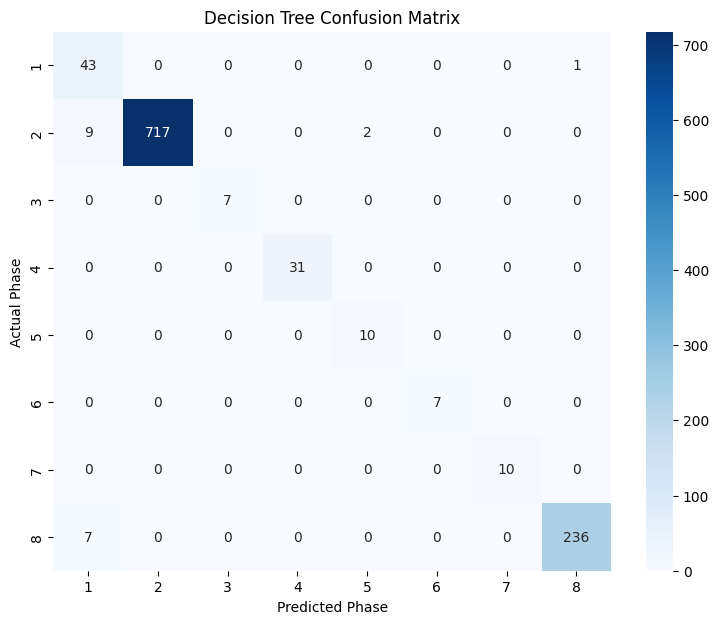

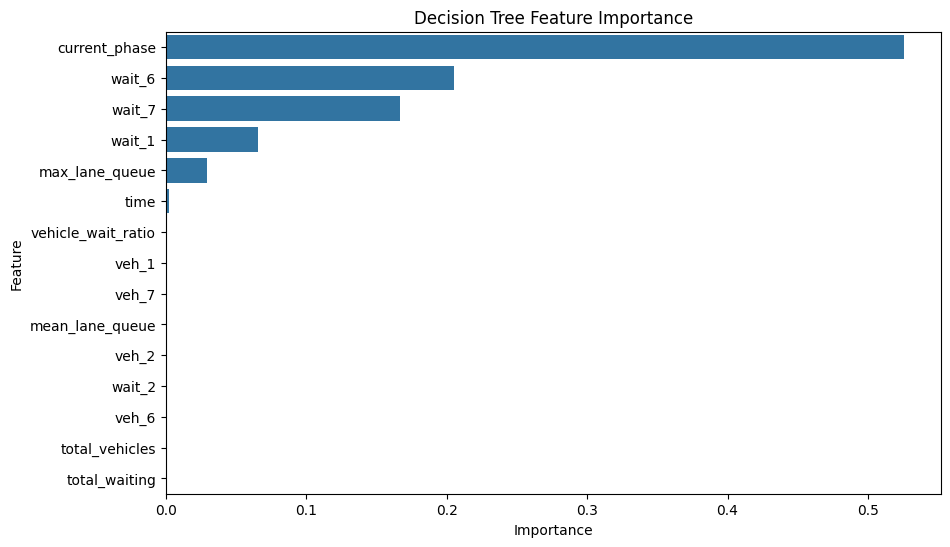

Training samples: 2880
Testing samples: 1080
Feature count: 15
TASK 5 COMPLETED


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

data = df.copy()

vehicle_cols = ['veh_1', 'veh_2', 'veh_6', 'veh_7']
waiting_cols = ['wait_1', 'wait_2', 'wait_6', 'wait_7']

data['total_vehicles'] = data[vehicle_cols].sum(axis=1)
data['total_waiting'] = data[waiting_cols].sum(axis=1)
data['max_lane_queue'] = data[waiting_cols].max(axis=1)
data['mean_lane_queue'] = data[waiting_cols].mean(axis=1)
data['vehicle_wait_ratio'] = (
    data['total_waiting'] / (data['total_vehicles'] + 1)
)

features = vehicle_cols + waiting_cols + [
    'time', 'current_phase', 'total_vehicles',
    'total_waiting', 'max_lane_queue',
    'mean_lane_queue', 'vehicle_wait_ratio'
]

X = data[features]
y = data['best_phase']

train_mask = data['episode'].isin([2, 3, 4, 5, 7, 8, 9, 11])
test_mask = data['episode'].isin([1, 6, 10])

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)

results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Decision Tree': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average='weighted', zero_division=0),
        recall_score(y_test, y_pred, average='weighted', zero_division=0),
        f1_score(y_test, y_pred, average='weighted', zero_division=0)
    ]
})

display(results)

print(classification_report(y_test, y_pred, zero_division=0))

plt.figure(figsize=(9, 7))
sns.heatmap(
    confusion_matrix(y_test, y_pred, labels=dt_model.classes_),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Phase')
plt.ylabel('Actual Phase')
plt.show()

importance = pd.DataFrame({
    'Feature': features,
    'Importance': dt_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x='Importance', y='Feature')
plt.title('Decision Tree Feature Importance')
plt.show()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Feature count:", len(features))
print("TASK 5 COMPLETED")


6) Logistic Regression Classification

,Metric,Logistic Regression
0,Accuracy,0.904630
1,Precision,0.940956
2,Recall,0.904630
3,F1 Score,0.917900



CLASSIFICATION REPORT

              precision    recall  f1-score   support

           1       0.72      0.70      0.71        44
           2       1.00      0.94      0.97       728
           3       0.21      0.86      0.33         7
           4       0.62      0.52      0.56        31
           5       0.33      0.90      0.49        10
           6       1.00      0.86      0.92         7
           7       0.33      1.00      0.50        10
           8       0.91      0.88      0.90       243

    accuracy                           0.90      1080
   macro avg       0.64      0.83      0.67      1080
weighted avg       0.94      0.90      0.92      1080



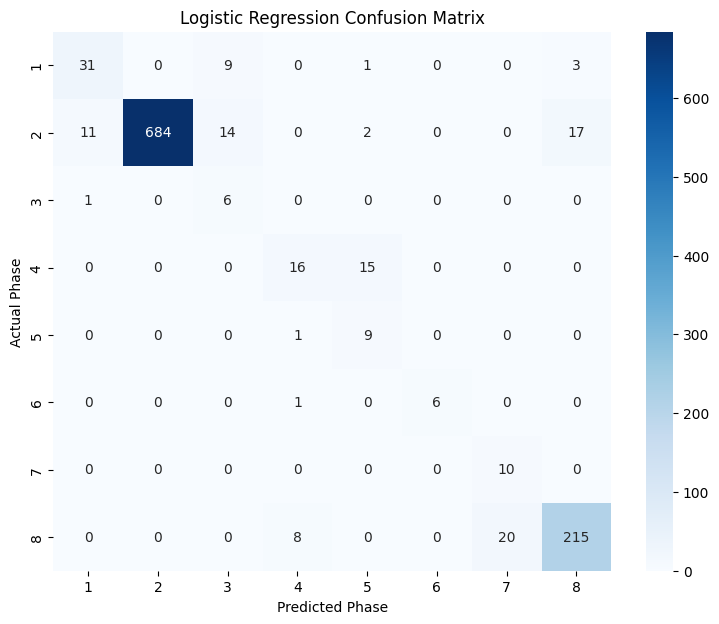

TASK 6 COMPLETED


In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

log_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=3000,
        class_weight='balanced',
        random_state=42
    ))
])

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

log_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_log, average='weighted', zero_division=0),
        recall_score(y_test, y_pred_log, average='weighted', zero_division=0),
        f1_score(y_test, y_pred_log, average='weighted', zero_division=0)
    ]
})

display(log_results)

print("\nCLASSIFICATION REPORT\n")
print(classification_report(y_test, y_pred_log, zero_division=0))

plt.figure(figsize=(9, 7))
sns.heatmap(
    confusion_matrix(y_test, y_pred_log, labels=log_model.classes_),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=log_model.classes_,
    yticklabels=log_model.classes_
)
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Phase')
plt.ylabel('Actual Phase')
plt.show()

print("TASK 6 COMPLETED")


7) Naive Bayes Classification

,Metric,Naive Bayes
0,Accuracy,0.773148
1,Precision,0.835857
2,Recall,0.773148
3,F1 Score,0.783996



CLASSIFICATION REPORT

              precision    recall  f1-score   support

           1       0.20      0.52      0.29        44
           2       0.88      0.88      0.88       728
           3       1.00      0.86      0.92         7
           4       0.39      1.00      0.56        31
           5       0.91      1.00      0.95        10
           6       1.00      1.00      1.00         7
           7       1.00      1.00      1.00        10
           8       0.84      0.45      0.59       243

    accuracy                           0.77      1080
   macro avg       0.78      0.84      0.77      1080
weighted avg       0.84      0.77      0.78      1080



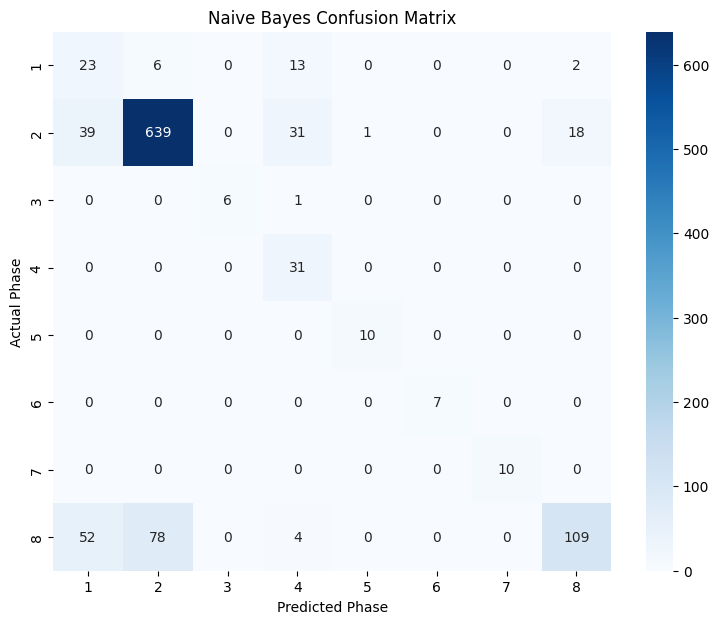

TASK 7 COMPLETED


In [14]:

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

nb_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Naive Bayes': [
        accuracy_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_nb, average='weighted', zero_division=0),
        recall_score(y_test, y_pred_nb, average='weighted', zero_division=0),
        f1_score(y_test, y_pred_nb, average='weighted', zero_division=0)
    ]
})

display(nb_results)

print("\nCLASSIFICATION REPORT\n")
print(classification_report(y_test, y_pred_nb, zero_division=0))

plt.figure(figsize=(9, 7))
sns.heatmap(
    confusion_matrix(y_test, y_pred_nb, labels=nb_model.classes_),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=nb_model.classes_,
    yticklabels=nb_model.classes_
)
plt.title('Naive Bayes Confusion Matrix')
plt.xlabel('Predicted Phase')
plt.ylabel('Actual Phase')
plt.show()

print("TASK 7 COMPLETED")


8) ANN implementation and activation comparison

In [16]:
train_episodes = [2, 3, 4, 5, 7, 8, 9, 11]
test_episodes = [1, 6, 10]


SIGMOID ACTIVATION
              precision    recall  f1-score   support

           1       0.60      0.86      0.71        44
           2       1.00      0.89      0.94       728
           3       0.30      1.00      0.47         7
           4       0.69      1.00      0.82        31
           5       0.91      1.00      0.95        10
           6       0.86      0.86      0.86         7
           7       0.43      1.00      0.61        10
           8       0.85      0.91      0.88       243

    accuracy                           0.90      1080
   macro avg       0.71      0.94      0.78      1080
weighted avg       0.93      0.90      0.91      1080



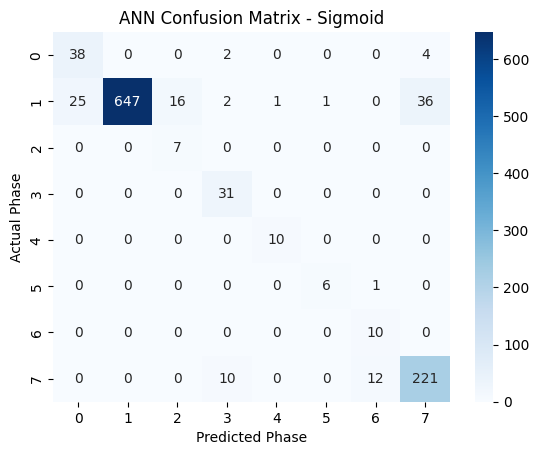


RELU ACTIVATION
              precision    recall  f1-score   support

           1       0.64      1.00      0.78        44
           2       1.00      0.95      0.97       728
           3       1.00      1.00      1.00         7
           4       0.79      1.00      0.89        31
           5       0.83      1.00      0.91        10
           6       1.00      1.00      1.00         7
           7       0.71      1.00      0.83        10
           8       0.96      0.95      0.95       243

    accuracy                           0.95      1080
   macro avg       0.87      0.99      0.92      1080
weighted avg       0.97      0.95      0.96      1080



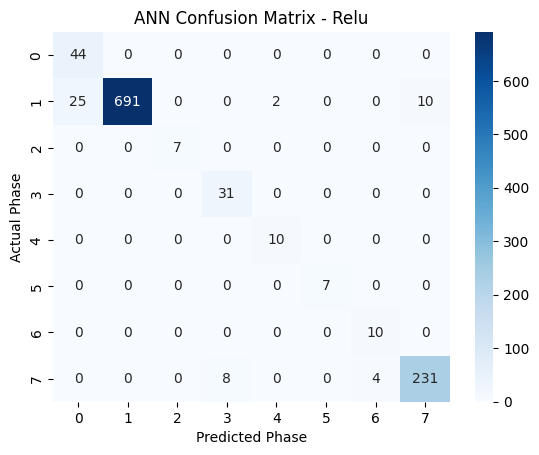


SOFTMAX ACTIVATION
              precision    recall  f1-score   support

           1       0.55      0.82      0.66        44
           2       0.98      0.93      0.96       728
           3       0.64      1.00      0.78         7
           4       0.58      0.48      0.53        31
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00         7
           7       0.26      1.00      0.41        10
           8       0.91      0.88      0.89       243

    accuracy                           0.89      1080
   macro avg       0.49      0.64      0.53      1080
weighted avg       0.91      0.89      0.90      1080



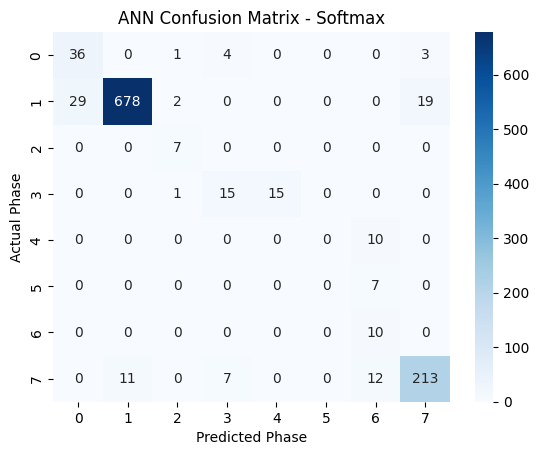

,Activation,Accuracy,Precision,Recall,F1 Score
0,Sigmoid,0.898148,0.928910,0.898148,0.907050
1,Relu,0.954630,0.965826,0.954630,0.957518
2,Softmax,0.887963,0.912871,0.887963,0.896418


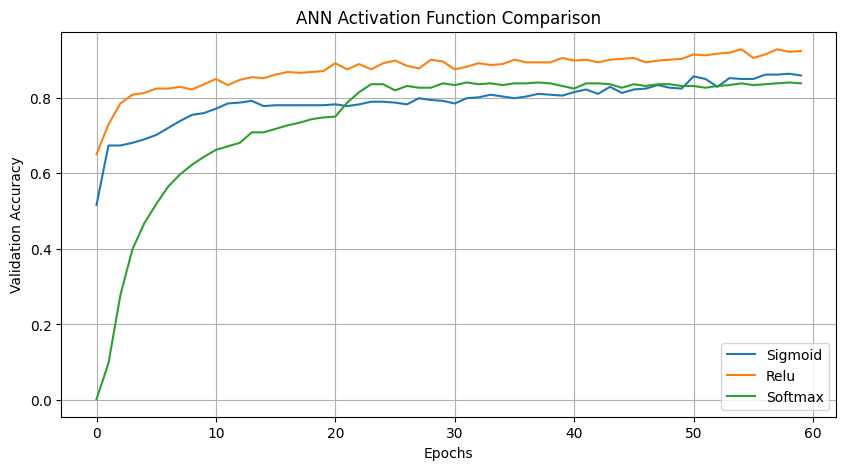

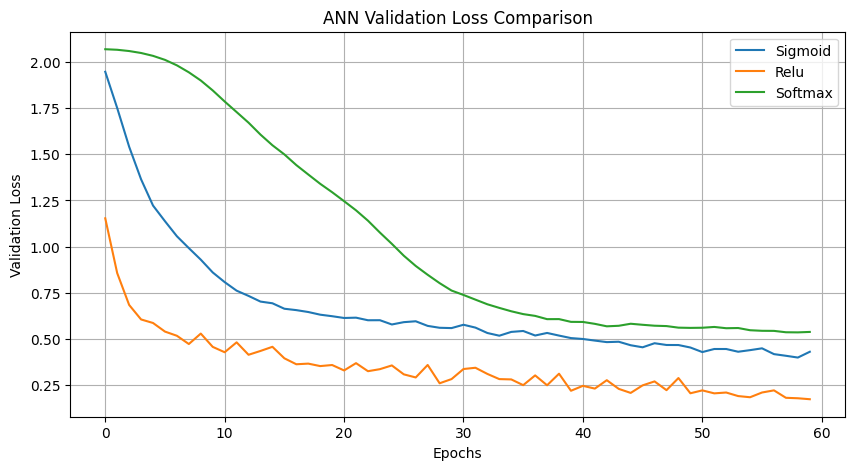

TASK 8 AND TASK 9 COMPLETED


In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

active_vehicles = ['veh_1', 'veh_2', 'veh_6', 'veh_7']
active_waiting = ['wait_1', 'wait_2', 'wait_6', 'wait_7']

feature_df = df.copy()

feature_df['total_vehicles'] = feature_df[active_vehicles].sum(axis=1)
feature_df['total_waiting'] = feature_df[active_waiting].sum(axis=1)
feature_df['max_lane_queue'] = feature_df[active_waiting].max(axis=1)
feature_df['mean_lane_queue'] = feature_df[active_waiting].mean(axis=1)
feature_df['vehicle_wait_ratio'] = (
    feature_df['total_waiting'] /
    (feature_df['total_vehicles'] + 1)
)

features = (
    active_vehicles +
    active_waiting +
    ['time', 'current_phase', 'total_vehicles',
     'total_waiting', 'max_lane_queue',
     'mean_lane_queue', 'vehicle_wait_ratio']
)

X_train = feature_df[feature_df['episode'].isin(train_episodes)][features]
X_test = feature_df[feature_df['episode'].isin(test_episodes)][features]

y_train = feature_df[feature_df['episode'].isin(train_episodes)]['best_phase'].values - 1
y_test = feature_df[feature_df['episode'].isin(test_episodes)]['best_phase'].values - 1

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

def build_ann(activation):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
        tf.keras.layers.Dense(64, activation=activation),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation=activation),
        tf.keras.layers.Dense(8, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

activation_functions = ['sigmoid', 'relu', 'softmax']

ann_results = []
ann_models = {}
ann_histories = {}

for activation in activation_functions:

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_ann(activation)

    history = model.fit(
        X_train_scaled,
        y_train,
        epochs=60,
        batch_size=32,
        validation_split=0.15,
        class_weight=class_weights,
        verbose=0
    )

    predictions = np.argmax(
        model.predict(X_test_scaled, verbose=0),
        axis=1
    )

    ann_models[activation] = model
    ann_histories[activation] = history

    ann_results.append({
        'Activation': activation.capitalize(),
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, predictions, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_test, predictions, average='weighted', zero_division=0)
    })

    print(f'\n{activation.upper()} ACTIVATION')
    print(classification_report(
        y_test,
        predictions,
        labels=np.arange(8),
        target_names=[str(i) for i in range(1, 9)],
        zero_division=0
    ))

    sns.heatmap(
        confusion_matrix(y_test, predictions, labels=np.arange(8)),
        annot=True,
        fmt='d',
        cmap='Blues'
    )
    plt.title(f'ANN Confusion Matrix - {activation.capitalize()}')
    plt.xlabel('Predicted Phase')
    plt.ylabel('Actual Phase')
    plt.show()

ann_comparison = pd.DataFrame(ann_results)

display(ann_comparison)

plt.figure(figsize=(10, 5))

for activation in activation_functions:
    plt.plot(
        ann_histories[activation].history['val_accuracy'],
        label=activation.capitalize()
    )

plt.title('ANN Activation Function Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))

for activation in activation_functions:
    plt.plot(
        ann_histories[activation].history['val_loss'],
        label=activation.capitalize()
    )

plt.title('ANN Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid()
plt.show()

print('TASK 8 AND TASK 9 COMPLETED')


9) Deep Q-Network (DQN) implementation

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import random
import warnings

warnings.filterwarnings("ignore")

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print("Libraries imported successfully.")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully.
TensorFlow version: 2.21.0


In [26]:
features = [
    'veh_1', 'veh_2', 'veh_6', 'veh_7',
    'wait_1', 'wait_2', 'wait_6', 'wait_7',
    'time', 'current_phase',
    'total_vehicles', 'total_waiting',
    'max_lane_queue', 'mean_lane_queue',
    'vehicle_wait_ratio'
]

train_episodes = [2, 3, 4, 5, 7, 8, 9, 11]
test_episodes = [1, 6, 10]

target_column = 'best_phase'

print("Features:", len(features))
print("Training episodes:", train_episodes)
print("Testing episodes:", test_episodes)

# Check required columns
required_columns = features + [
    target_column, 'episode'
]

missing_columns = [
    col for col in required_columns
    if col not in feature_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in feature_df: {missing_columns}"
    )

print("All required columns are available.")

Features: 15
Training episodes: [2, 3, 4, 5, 7, 8, 9, 11]
Testing episodes: [1, 6, 10]
All required columns are available.


In [27]:
# Split by episode
train_df = feature_df[
    feature_df['episode'].isin(train_episodes)
].copy()

test_df = feature_df[
    feature_df['episode'].isin(test_episodes)
].copy()

# Remove rows with missing required values
train_df = train_df.dropna(
    subset=features + [target_column]
)

test_df = test_df.dropna(
    subset=features + [target_column]
)

# Feature matrices
X_train = train_df[features].astype(float)
X_test = test_df[features].astype(float)

# Target labels: original phases 1-8
y_train = train_df[target_column].astype(int)
y_test = test_df[target_column].astype(int)

# Validate phase labels
valid_phases = set(range(1, 9))

if not set(y_train.unique()).issubset(valid_phases):
    raise ValueError("Invalid training phase labels.")

if not set(y_test.unique()).issubset(valid_phases):
    raise ValueError("Invalid testing phase labels.")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Feature count:", X_train.shape[1])

print("\nTraining phase distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting phase distribution:")
print(y_test.value_counts().sort_index())

Training samples: 2880
Testing samples: 1080
Feature count: 15

Training phase distribution:
best_phase
1     191
2    2030
3      31
4      60
5      40
6      23
7      22
8     483
Name: count, dtype: int64

Testing phase distribution:
best_phase
1     44
2    728
3      7
4     31
5     10
6      7
7     10
8    243
Name: count, dtype: int64


In [28]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = X_train_scaled.astype(np.float32)
X_test_scaled = X_test_scaled.astype(np.float32)

# Check numerical stability
assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_test_scaled).all()

print("Feature normalization completed.")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("All values finite:", np.isfinite(X_train_scaled).all())

Feature normalization completed.
Training shape: (2880, 15)
Testing shape: (1080, 15)
All values finite: True


In [29]:
NUM_ACTIONS = 8

# Convert phases 1-8 into action indices 0-7
y_train_actions = y_train.to_numpy() - 1
y_test_actions = y_test.to_numpy() - 1

# Reward matrix:
# +1 for the recorded best phase
# -1 for all other phases

reward_targets = -np.ones(
    (len(y_train_actions), NUM_ACTIONS),
    dtype=np.float32
)

reward_targets[
    np.arange(len(y_train_actions)),
    y_train_actions
] = 1.0

print("Number of actions:", NUM_ACTIONS)
print("Reward matrix shape:", reward_targets.shape)

print("\nExample action labels:")
print(y_train_actions[:10])

print("\nExample reward targets:")
print(reward_targets[:3])

Number of actions: 8
Reward matrix shape: (2880, 8)

Example action labels:
[0 2 1 4 1 7 7 7 6 3]

Example reward targets:
[[ 1. -1. -1. -1. -1. -1. -1. -1.]
 [-1. -1.  1. -1. -1. -1. -1. -1.]
 [-1.  1. -1. -1. -1. -1. -1. -1.]]


In [30]:
def build_dqn(state_size, action_size):

    model = Sequential([
        Input(shape=(state_size,)),

        Dense(128, activation='relu'),
        Dense(128, activation='relu'),

        Dense(action_size, activation='linear')
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.0001,
            clipnorm=1.0
        ),
        loss=tf.keras.losses.Huber()
    )

    return model


state_size = X_train_scaled.shape[1]
action_size = NUM_ACTIONS

dqn = build_dqn(state_size, action_size)

dqn.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,592 (76.53 KB)

 Trainable params: 19,592 (76.53 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# Fresh DQN initialization
dqn = build_dqn(state_size, action_size)

# Check all model weights
weights_finite = all(
    np.isfinite(w).all()
    for w in dqn.get_weights()
)

# Check initial predictions
initial_q_values = dqn.predict(
    X_train_scaled[:10],
    verbose=0
)

print("DQN INITIALIZATION DIAGNOSTICS")

print("Weights finite:", weights_finite)

print(
    "Q-values finite:",
    np.isfinite(initial_q_values).all()
)

print("Initial Q-value range:")
print("Minimum:", np.min(initial_q_values))
print("Maximum:", np.max(initial_q_values))

assert weights_finite, "Non-finite initial weights!"
assert np.isfinite(initial_q_values).all(), "Invalid initial Q-values!"

print("\nDQN initialization successful.")

DQN INITIALIZATION DIAGNOSTICS
Weights finite: True
Q-values finite: True
Initial Q-value range:
Minimum: -0.5626761
Maximum: 0.47375274

DQN initialization successful.


In [32]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True,
    min_delta=0.0001
)

print("Starting DQN training...")

dqn_history = dqn.fit(
    X_train_scaled,
    reward_targets,

    epochs=100,
    batch_size=64,

    validation_split=0.2,

    callbacks=[early_stopping],

    verbose=1,
    shuffle=True
)

print("\nDQN training completed.")

final_loss = dqn_history.history['loss'][-1]

print("Final training loss:", final_loss)

# Verify trained model
trained_weights_finite = all(
    np.isfinite(w).all()
    for w in dqn.get_weights()
)

print("Trained weights finite:", trained_weights_finite)

assert trained_weights_finite, (
    "Training produced non-finite weights."
)

assert np.isfinite(final_loss), (
    "Training loss is not finite."
)

Starting DQN training...
Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.4183 - val_loss: 0.3324
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2717 - val_loss: 0.2100
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1833 - val_loss: 0.1600
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1384 - val_loss: 0.1385
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1148 - val_loss: 0.1209
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1002 - val_loss: 0.1068
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0905 - val_loss: 0.0967
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0836 - val_loss: 0.0893
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0783 - val_loss: 0.0838
Epoch 10/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0742 - val_loss: 0.0795
Epoch 11/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0709 - val_loss: 0.0761
Epoch 12/100
36/36 ━━━━━━━━━━━━━━

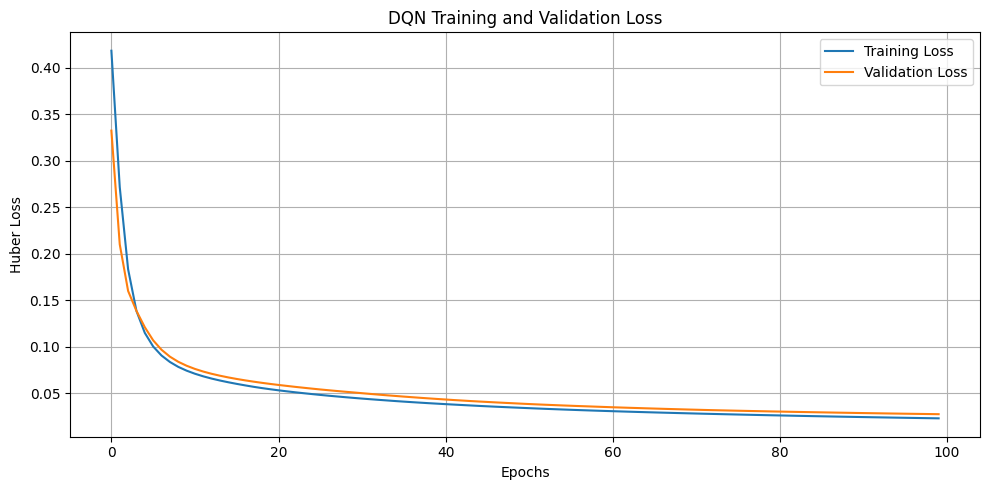

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    dqn_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    dqn_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('DQN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Huber Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
# Generate Q-values
q_values = dqn.predict(
    X_test_scaled,
    verbose=0
)

# Numerical validation
assert np.isfinite(q_values).all(), (
    "Predicted Q-values contain NaN or Inf."
)

# Select action with maximum Q-value
predicted_actions = np.argmax(
    q_values,
    axis=1
)

# Convert action indices 0-7 back to phases 1-8
y_pred_dqn = predicted_actions + 1

print("DQN predictions completed.")

print("Predicted Q-value shape:", q_values.shape)

print("First 20 predicted phases:")
print(y_pred_dqn[:20])

print("All Q-values finite:", np.isfinite(q_values).all())

print("Minimum Q-value:", np.min(q_values))
print("Maximum Q-value:", np.max(q_values))

DQN predictions completed.
Predicted Q-value shape: (1080, 8)
First 20 predicted phases:
[1 1 1 1 1 1 1 1 1 1 5 5 5 5 5 5 5 5 5 8]
All Q-values finite: True
Minimum Q-value: -1.4947457
Maximum Q-value: 1.56232


In [35]:
dqn_accuracy = accuracy_score(
    y_test,
    y_pred_dqn
)

dqn_precision = precision_score(
    y_test,
    y_pred_dqn,
    average='weighted',
    zero_division=0
)

dqn_recall = recall_score(
    y_test,
    y_pred_dqn,
    average='weighted',
    zero_division=0
)

dqn_f1 = f1_score(
    y_test,
    y_pred_dqn,
    average='weighted',
    zero_division=0
)

dqn_results = pd.DataFrame({
    'Model': ['DQN'],
    'Accuracy': [dqn_accuracy],
    'Precision': [dqn_precision],
    'Recall': [dqn_recall],
    'F1 Score': [dqn_f1]
})

print("DQN PERFORMANCE")
display(dqn_results)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_dqn,
        labels=list(range(1, 9)),
        zero_division=0
    )
)

DQN PERFORMANCE


,Model,Accuracy,Precision,Recall,F1 Score
0,DQN,0.922222,0.911976,0.922222,0.913569



Classification Report:
              precision    recall  f1-score   support

           1       0.63      0.86      0.73        44
           2       0.98      0.98      0.98       728
           3       0.00      0.00      0.00         7
           4       0.53      0.26      0.35        31
           5       0.30      0.90      0.45        10
           6       0.00      0.00      0.00         7
           7       0.00      0.00      0.00        10
           8       0.92      0.94      0.93       243

    accuracy                           0.92      1080
   macro avg       0.42      0.49      0.43      1080
weighted avg       0.91      0.92      0.91      1080



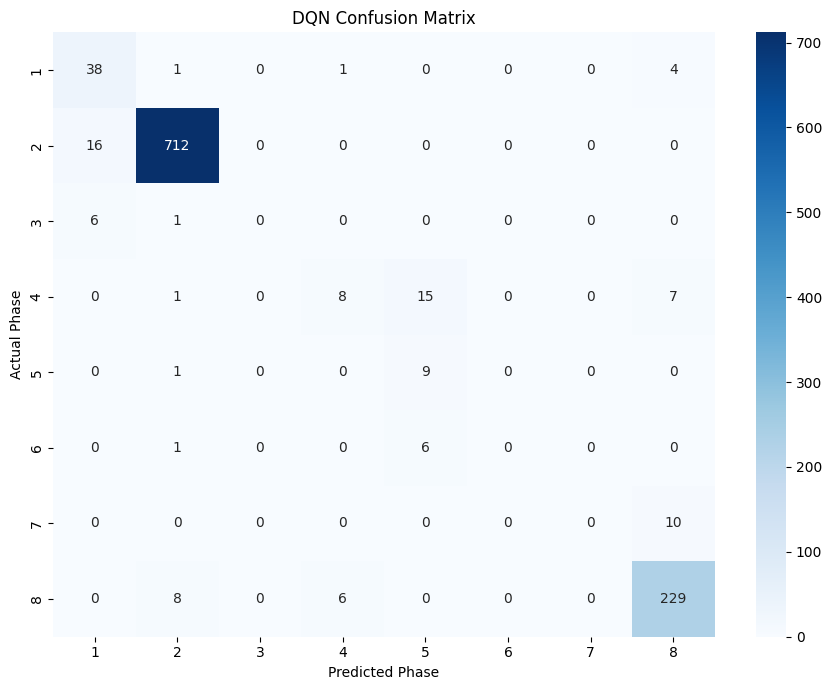

In [36]:
cm_dqn = confusion_matrix(
    y_test,
    y_pred_dqn,
    labels=list(range(1, 9))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_dqn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(1, 9),
    yticklabels=range(1, 9)
)

plt.title('DQN Confusion Matrix')
plt.xlabel('Predicted Phase')
plt.ylabel('Actual Phase')

plt.tight_layout()
plt.show()

In [37]:
comparison_df = pd.DataFrame({
    'Model': ['ANN (ReLU)', 'DQN'],

    'Accuracy': [
        0.954630,
        dqn_accuracy
    ],

    'Precision': [
        0.965826,
        dqn_precision
    ],

    'Recall': [
        0.954630,
        dqn_recall
    ],

    'F1 Score': [
        0.957518,
        dqn_f1
    ]
})

print("ANN vs DQN PERFORMANCE COMPARISON")

display(comparison_df)

ANN vs DQN PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,ANN (ReLU),0.954630,0.965826,0.954630,0.957518
1,DQN,0.922222,0.911976,0.922222,0.913569


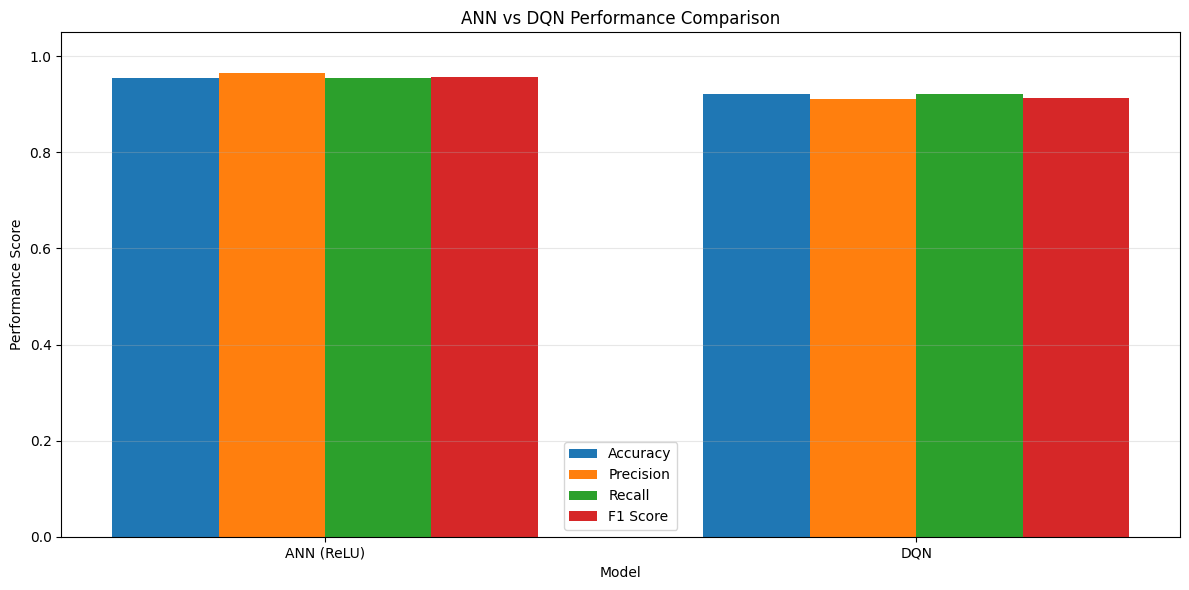

In [38]:
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score'
]

x = np.arange(len(comparison_df))
width = 0.18

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):

    plt.bar(
        x + (i - 1.5) * width,
        comparison_df[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    comparison_df['Model']
)

plt.ylabel('Performance Score')
plt.xlabel('Model')

plt.title('ANN vs DQN Performance Comparison')

plt.ylim(0, 1.05)

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
dqn.save('traffic_signal_dqn.keras')

import joblib

joblib.dump(
    scaler,
    'traffic_signal_scaler.pkl'
)

print("DQN model saved successfully.")
print("Scaler saved successfully.")

DQN model saved successfully.
Scaler saved successfully.
